# DIP Assignment 1 — Problem 3: Piecewise linear transforms

**Name:** Kushal Mukherjee &nbsp;&nbsp; **Roll number:** 2025201072

In [1]:
import time
import platform
import subprocess

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

ROOT = Path.cwd()

print("CPU    :", subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip())
print("Cores  :", subprocess.check_output(["sysctl", "-n", "hw.ncpu"]).decode().strip())
print("RAM    :", round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"])) / 1e9), "GB")
print("OS     :", platform.platform())
print("Python :", platform.python_version())
print("NumPy  :", np.__version__)

CPU    : Apple M4
Cores  : 10
RAM    : 17 GB
OS     : macOS-15.7.7-arm64-arm-64bit-Mach-O
Python : 3.13.9
NumPy  : 2.4.1


---
# Problem 3 — Piecewise linear transforms

One pointwise piecewise-linear transform was applied to each input/output pair:

- A: `field_in.png` -> `field_out_A.png` (levels operation)
- B: `field_in.png` -> `field_out_B.png` (grey-level slicing, not monotonic)
- C: `nebula_in.png` -> `nebula_out_C.png` (segment count not given)
- D: `field_skycrop_in.png` -> `field_skycrop_out_D.png` (mostly sky, four true segments)

In [2]:
def load_p3(name):
    return np.asarray(Image.open(ROOT / "images/p3" / name).convert("L"))


def transfer_curve(img_in, img_out):
    """T[v] = the output level for input level v, cnt[v] = pixels supporting it.

    Unsampled levels get T = nan, so they stay distinguishable from levels that
    genuinely map to zero.
    """
    cnt = np.bincount(img_in.ravel(), minlength=256).astype(float)
    T = np.full(256, np.nan)

    for v in np.flatnonzero(cnt):
        T[v] = np.median(img_out[img_in == v])

    return T, cnt

In [3]:
QUANT_FLOOR = 1 / 12    # variance of rounding a real number to the nearest integer


def fit_piecewise(T, cnt, max_seg=6, min_count=1, force_seg=None):
    """Fit the fewest segments the data justifies.

    The output is an 8-bit lookup table, so rounding alone leaves a mean squared
    residual of about 1/12. Once a fit reaches that floor it is describing the
    quantisation rather than the transform, so we stop there.

    Returns (breakpoints, slopes, intercepts, n_segments, rss_by_segment_count).
    """
    v = np.flatnonzero((cnt >= min_count) & ~np.isnan(T)).astype(float)
    y = T[v.astype(int)]
    m = len(v)

    # sse[i, j] = squared error of one straight line through levels v[i:j]
    sse = np.full((m + 1, m + 1), np.inf)
    for i in range(m):
        for j in range(i + 2, m + 1):
            x, yy = v[i:j], y[i:j]
            dx = x - x.mean()
            slope = (dx * (yy - yy.mean())).sum() / (dx * dx).sum()
            sse[i, j] = np.sum((slope * x + (yy.mean() - slope * x.mean()) - yy) ** 2)

    # best[s, j] = lowest error using s segments to cover the first j levels
    best = np.full((max_seg + 1, m + 1), np.inf)
    best[0, 0] = 0.0
    back = np.zeros((max_seg + 1, m + 1), dtype=int)

    for s in range(1, max_seg + 1):
        for j in range(2 * s, m + 1):
            for i in range(2 * (s - 1), j - 1):
                total = best[s - 1, i] + sse[i, j]
                if total < best[s, j]:
                    best[s, j] = total
                    back[s, j] = i

    rss = best[1:, m]

    # smallest segment count whose residual has reached the quantisation floor
    ok = np.flatnonzero(rss / m <= QUANT_FLOOR)
    n_seg = int(ok[0]) + 1 if len(ok) else max_seg

    if force_seg is not None:
        n_seg = force_seg

    # walk the choices back to get the segments
    bps, slopes, inters = [], [], []
    j, s = m, n_seg
    while s > 0:
        i = back[s, j]
        x, yy = v[i:j], y[i:j]
        dx = x - x.mean()
        slope = (dx * (yy - yy.mean())).sum() / (dx * dx).sum()
        bps.append((v[i], v[j - 1]))
        slopes.append(slope)
        inters.append(yy.mean() - slope * x.mean())
        j, s = i, s - 1

    return bps[::-1], slopes[::-1], inters[::-1], n_seg, rss

In [4]:
def apply_recovered(img, bps, slopes, inter):
    """Build the LUT from the fitted segments and apply it."""
    lut = np.zeros(256)

    for (lo, hi), s, c in zip(bps, slopes, inter):
        v = np.arange(int(lo), int(hi) + 1)
        lut[v] = s * v + c

    return np.clip(np.round(lut), 0, 255).astype(np.uint8)[img]


def support_report(cnt, min_count=20):
    """Which intensity ranges the input samples well enough to constrain T."""
    sup = np.flatnonzero(cnt >= min_count)
    weak = np.flatnonzero((cnt > 0) & (cnt < min_count))

    lines = [f"threshold: a level needs at least {min_count} pixels",
             f"trusted levels : {len(sup)} of 256, spanning {sup.min()}-{sup.max()}",
             f"too few pixels : {len(weak)} levels",
             f"never sampled  : {int(np.sum(cnt == 0))} levels"]

    return "\n".join(lines)


def show_fit(T, cnt, bps, slopes, inter, title):
    """Measured scatter with the fitted curve on top."""
    v = np.flatnonzero(~np.isnan(T))

    plt.figure(figsize=(7, 5))
    plt.scatter(v, T[v], s=8, label="measured T[v]")
    for (lo, hi), s, c in zip(bps, slopes, inter):
        x = np.arange(int(lo), int(hi) + 1)
        plt.plot(x, s * x + c, "r-", lw=2)
    plt.plot([], [], "r-", lw=2, label="fitted segments")
    plt.xlabel("input level v")
    plt.ylabel("output level T[v]")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

## 3.1 — Recover two known transforms

### A: levels operation

segments chosen: 3

   input range     slope   intercept
        0 - 12     0.000        0.00
       13 - 60     3.969      -48.36
      61 - 255     0.333      169.66

re-applied against true output: max |err| = 0, mean |err| = 0.0000


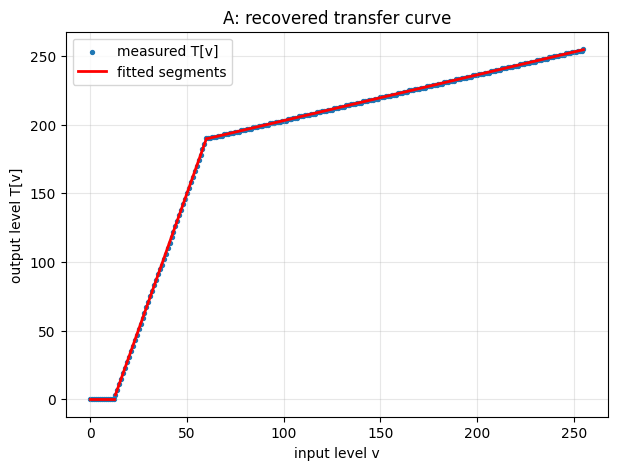

In [5]:
inA = load_p3("field_in.png")
outA = load_p3("field_out_A.png")

TA, cntA = transfer_curve(inA, outA)
bpsA, slA, itA, nA, rssA = fit_piecewise(TA, cntA)

print(f"segments chosen: {nA}\n")
print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsA, slA, itA):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

recA = apply_recovered(inA, bpsA, slA, itA)
err = np.abs(recA.astype(int) - outA.astype(int))
print(f"\nre-applied against true output: max |err| = {err.max()}, mean |err| = {err.mean():.4f}")

show_fit(TA, cntA, bpsA, slA, itA, "A: recovered transfer curve")

### B: grey-level slicing

segments chosen: 4

   input range     slope   intercept
        0 - 69     0.285       -0.40
      70 - 110     5.375     -356.64
     111 - 150    -5.373      825.54
     151 - 255    -0.190       48.03

re-applied against true output: max |err| = 0, mean |err| = 0.0000


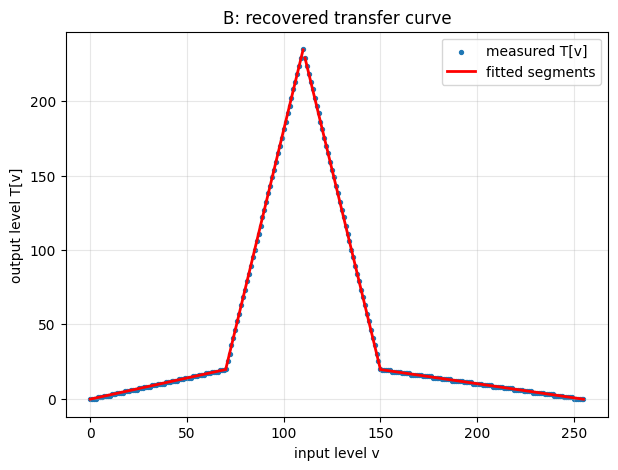

In [6]:
inB = load_p3("field_in.png")
outB = load_p3("field_out_B.png")

TB, cntB = transfer_curve(inB, outB)
bpsB, slB, itB, nB, rssB = fit_piecewise(TB, cntB)

print(f"segments chosen: {nB}\n")
print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsB, slB, itB):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

recB = apply_recovered(inB, bpsB, slB, itB)
err = np.abs(recB.astype(int) - outB.astype(int))
print(f"\nre-applied against true output: max |err| = {err.max()}, mean |err| = {err.mean():.4f}")

show_fit(TB, cntB, bpsB, slB, itB, "B: recovered transfer curve")

**B is recoverable from the pair but not invertible from the output alone. Explain the
difference in one sentence.**

From the pair I can see which output each input level produced, so T is fully determined,
but from the output alone I cannot undo it, because slicing is not monotonic and several
input levels map to the same output, so no unique inverse exists.

## 3.2 — Choose the number of segments

C is not told how many segments it has, so the count has to come from the data.

 segments          RSS   RSS / level
        1    190530.82      750.1214
        2     19158.12       75.4257
        3       639.86        2.5191
        4        20.46        0.0806  <- chosen
        5        20.05        0.0789
        6        19.64        0.0773

quantisation floor = 1/12 = 0.0833
segments chosen    = 4

   input range     slope   intercept
        1 - 39     0.376        4.53
      40 - 120     2.250      -70.35
     121 - 198     0.313      161.94
     199 - 255     0.545      115.64

re-applied against true output: max |err| = 0, mean |err| = 0.0000


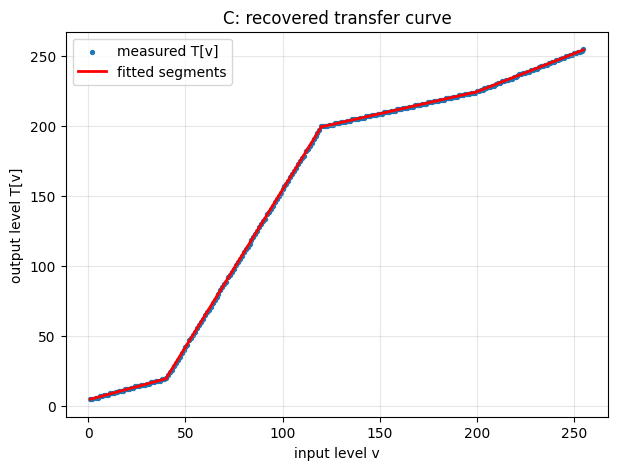

In [7]:
inC = load_p3("nebula_in.png")
outC = load_p3("nebula_out_C.png")

TC, cntC = transfer_curve(inC, outC)
bpsC, slC, itC, nC, rssC = fit_piecewise(TC, cntC)

m = int(np.sum(~np.isnan(TC)))

print(f"{'segments':>9} {'RSS':>12} {'RSS / level':>13}")
for s, r in enumerate(rssC, 1):
    mark = "  <- chosen" if s == nC else ""
    print(f"{s:9d} {r:12.2f} {r / m:13.4f}{mark}")

print(f"\nquantisation floor = 1/12 = {1 / 12:.4f}")
print(f"segments chosen    = {nC}\n")

print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsC, slC, itC):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

recC = apply_recovered(inC, bpsC, slC, itC)
err = np.abs(recC.astype(int) - outC.astype(int))
print(f"\nre-applied against true output: max |err| = {err.max()}, mean |err| = {err.mean():.4f}")

show_fit(TC, cntC, bpsC, slC, itC, "C: recovered transfer curve")

### Forcing more segments than the data supports

In [8]:
# force more segments than the data supports and look at what they do
bps6, sl6, it6, _, _ = fit_piecewise(TC, cntC, force_seg=6)

print("forced 6-segment fit:")
print(f"{'input range':>14} {'slope':>9}")
for (lo, hi), sl in zip(bps6, sl6):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {sl:9.3f}")

print(f"\nRSS at {nC} segments: {rssC[nC - 1]:.2f}   at 6 segments: {rssC[5]:.2f}")
print(f"improvement: {rssC[nC - 1] - rssC[5]:.2f} over {6 - nC} extra segments")

forced 6-segment fit:
   input range     slope
        1 - 39     0.376
      40 - 119     2.249
     120 - 123     0.000
     124 - 198     0.313
     199 - 252     0.545
     253 - 255     1.000

RSS at 4 segments: 20.46   at 6 segments: 19.64
improvement: 0.82 over 2 extra segments


**State the complexity penalty you used and why, and show that your method is not fitting the
quantisation of the output lookup table.**

**The penalty.** A least-squares fit only ever improves when you add segments, so I need a
stopping rule instead of just minimising error. The rule I used is: stop at the smallest
number of segments whose residual per level has reached 1/12.

1/12 comes from the output itself. The output is an 8-bit LUT, so every value has already
been rounded to an integer. Rounding a real number to the nearest integer leaves an error
that is roughly uniform on [-0.5, 0.5], and that has variance 1/12 = 0.0833. So 0.0833 is
the smallest residual that can possibly mean anything. Anything below it is not error in my
fit, it is the rounding that was baked into the data before I ever saw it.

For C the residual per level goes 750.12, 75.43, 2.52, then 0.0806 at four segments. Four is
the first count that reaches the floor, so I report four.

**That it does not fit the quantisation.** Forcing six segments on the same data gives:

| range | slope |
|---|---|
| 1 - 39 | 0.376 |
| 40 - 119 | 2.249 |
| 120 - 123 | 0.000 |
| 124 - 198 | 0.313 |
| 199 - 252 | 0.545 |
| 253 - 255 | 1.000 |

The two extra segments are 120-123 and 253-255, only four and three levels wide, with slopes
of exactly 0.000 and 1.000. These are not real pieces of the transform. They are single steps
of the rounding staircase, and the fit has split a true slope into flat and integer-valued
pieces to chase them. The whole gain from four segments to six is 20.46 down to 19.64 in RSS,
which is nothing. My rule stops at four and never sees these.

## 3.3 — Identifiability

D is a crop of almost nothing but sky, so only a narrow band of input levels is well sampled.

threshold: a level needs at least 20 pixels
trusted levels : 63 of 256, spanning 1-75
too few pixels : 176 levels
never sampled  : 17 levels


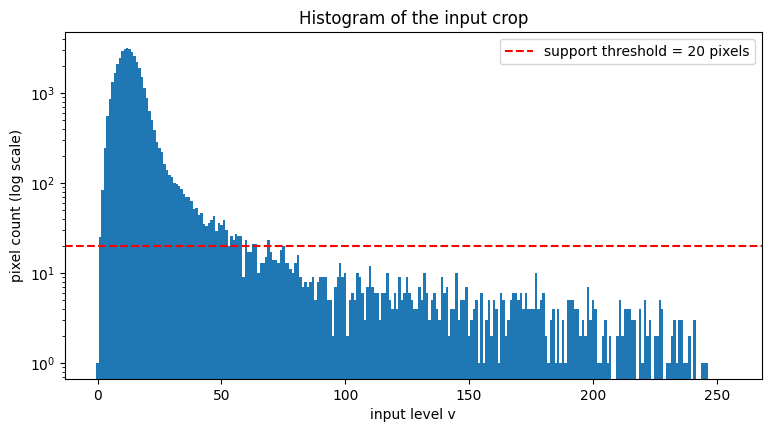

In [9]:
inD = load_p3("field_skycrop_in.png")
outD = load_p3("field_skycrop_out_D.png")

TD, cntD = transfer_curve(inD, outD)

MIN_COUNT = 20

print(support_report(cntD, MIN_COUNT))

plt.figure(figsize=(9, 4.5))
plt.bar(np.arange(256), cntD, width=1.0)
plt.axhline(MIN_COUNT, color="r", ls="--", label=f"support threshold = {MIN_COUNT} pixels")
plt.yscale("log")
plt.xlabel("input level v")
plt.ylabel("pixel count (log scale)")
plt.title("Histogram of the input crop")
plt.legend()
plt.show()

segments the data supports: 3

   input range     slope   intercept
        1 - 20     1.504       -0.29
       21 - 55     4.863      -67.78
       56 - 75     0.330      181.19

constrained over levels 1 - 75
unconstrained above level 75: 163 levels carry pixels but fewer than 20 each


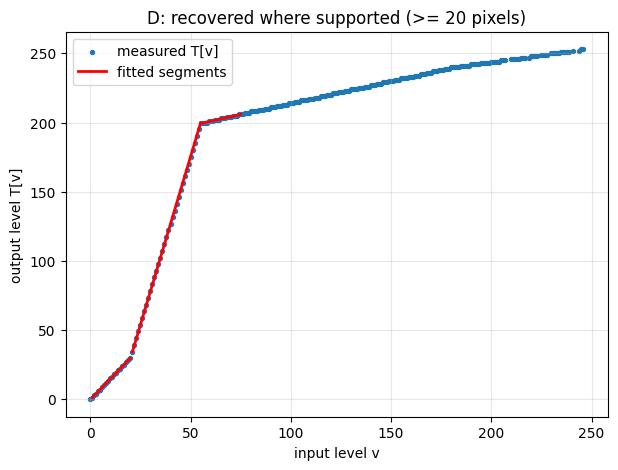

In [10]:
bpsD, slD, itD, nD, rssD = fit_piecewise(TD, cntD, min_count=MIN_COUNT)

sup = np.flatnonzero(cntD >= MIN_COUNT)

print(f"segments the data supports: {nD}\n")
print(f"{'input range':>14} {'slope':>9} {'intercept':>11}")
for (lo, hi), s, c in zip(bpsD, slD, itD):
    print(f"{f'{lo:.0f} - {hi:.0f}':>14} {s:9.3f} {c:11.2f}")

print(f"\nconstrained over levels {sup.min()} - {sup.max()}")
print(f"unconstrained above level {sup.max()}: "
      f"{int(np.sum((cntD > 0) & (np.arange(256) > sup.max())))} levels carry pixels "
      f"but fewer than {MIN_COUNT} each")

show_fit(TD, cntD, bpsD, slD, itD, f"D: recovered where supported (>= {MIN_COUNT} pixels)")

**(a) State the range of input levels actually sampled and justify your support threshold.**

The crop is 200x200, so 40000 pixels. Every level from 0 to 246 has at least something, but
the histogram (log scale above) shows most of them have only a handful of pixels. Levels
above about 75 are nearly empty.

I trust T[v] only where a level has at least 20 pixels. I picked 20 because T[v] is read off
the pixels at that level, so with only two or three pixels a single stray value would set the
whole answer, and 20 pixels is 0.05% of the crop, which is low enough to keep everything that
is genuinely sky but high enough to throw out the stragglers. With that threshold, 63 levels
are trusted and they span 1 to 75. 176 levels have fewer than 20 pixels and 17 levels have
none at all.

**(b) Report the segments you can determine and the intensity range over which your answer is
unconstrained.**

Over levels 1 to 75 the data supports three segments:

| input range | slope | intercept |
|---|---|---|
| 1 - 20 | 1.504 | -0.29 |
| 21 - 55 | 4.863 | -67.78 |
| 56 - 75 | 0.330 | 181.19 |

Above level 75 my answer is unconstrained. Pixels do exist up to 246, but never more than 19
at a level, so I cannot tell the transform from the noise there. Any curve at all could be
put above 75 and it would fit the data just as well.

**(c) How many segments did you report, and why is that not four?**

I reported three, and the true transform has four. The missing one lives above level 75, in
the range the crop does not sample. This is not a failure of the fitting method. The crop is
almost all sky, so it only contains dark pixels, and a transform is only visible at the input
levels that actually occur. Where no pixels occur the data says nothing, and no method can
recover a parameter the data does not constrain. Reporting four here would mean inventing the
fourth one, so the correct answer is to report three and say where the gap is.